# A Demo of IML-ViT

This notebook provides a example of our training & inference pipeline of how to apply IML-ViT to image manipulation localization tasks.

### Requirements
You should install the requirements in `./requirements.txt` and manually install following requirements before run this note book：
- PyTorch
- OpenCV (cv2)

### Load Dataset
- We defined two types of Dataset class
  - `json_dataset`, which get input image and correspoding groundtruth from a json file with protocol like this:
    ```
    [
        [
          "/Dataset/CASIAv1/Tp/image1.jpg",
          "/Dataset/CASIAv2/Gt/image1.jpg"
        ],
        [
          "/Dataset/CASIAv1/Tp/image2.jpg",
          "Negative"
        ],
        ......
    ]
    ```
    where "Negative" represent a totally black groundtruth that don't needs a path(all authentic)
  - `mani_dataset` which loads image and groundtruth pairs automaticlly from a directory having sub-directories named as `Tp` (for input images) and `Gt` |(for groundtruths). This class will use sorted `os.listdir()` function to generate the pairs. 
- These datasets will do **zero-padding** automatically. Common augumentation method like ImageNet normalization will also be added.
- Both datasets can generate `edge_mask` when specify the `edge_width` parameter. Then, this dataset will return 3 objects (image, GT, edge mask) while only 2 objects when `edge_width=None`.
- For inference, returing the actual shape of the original image is crucial. You can set `if_return_shape=True` to get this value. 

In [4]:
# Pre-import and set for a clear ploting
from matplotlib import pyplot as plt
plt.rcParams['figure.dpi'] = 60
plt.rcParams['font.size'] = 10
plt.rcParams['figure.figsize'] = (24, 6)
from utils.datasets import mani_dataset # special Dataset class

In [5]:
# here we use mani dataset as example
input_dir = "./images/sample_iml_dataset/"
dataset = mani_dataset(
    path = input_dir,
    edge_width=7, # specify the edge mask, other wise only return 2 objects
    if_return_shape=True
)
print(dataset)
print("len:", len(dataset))

len: 11


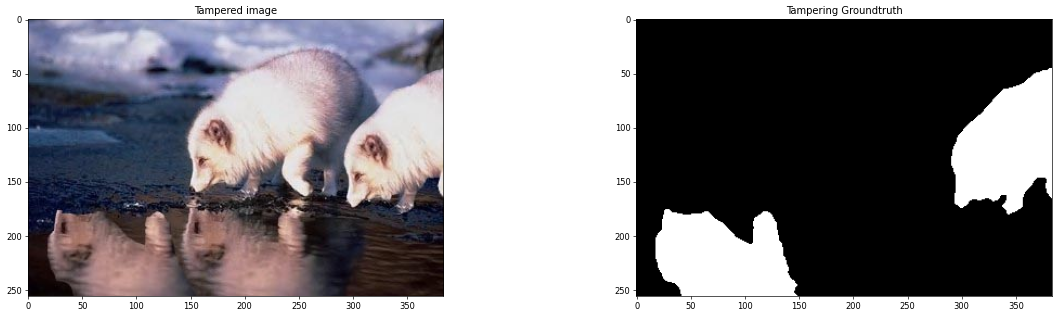

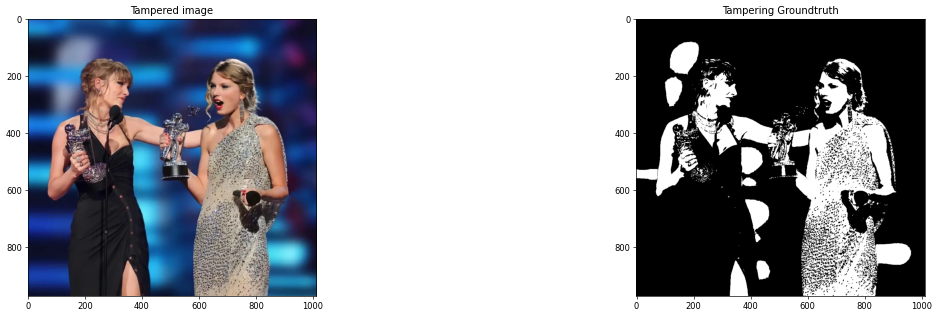

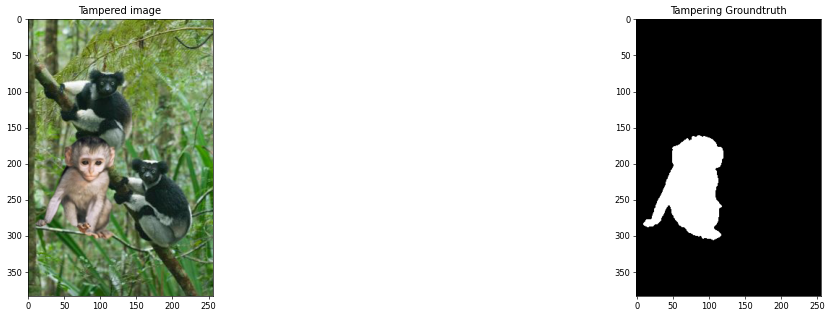

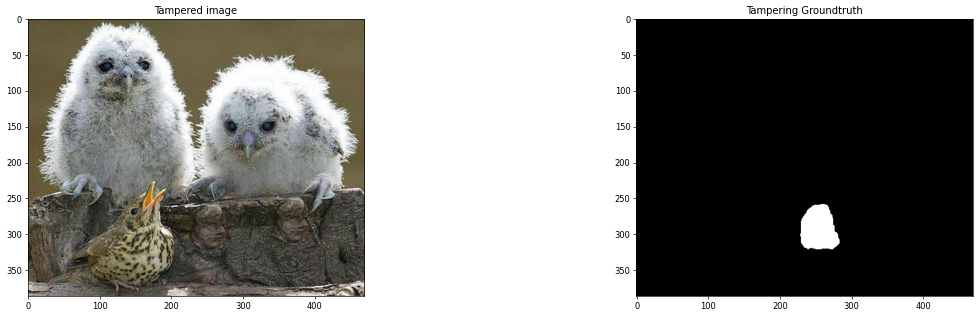

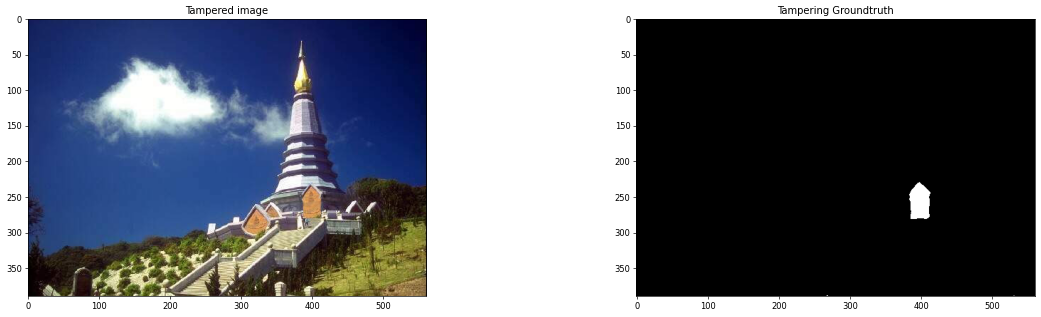

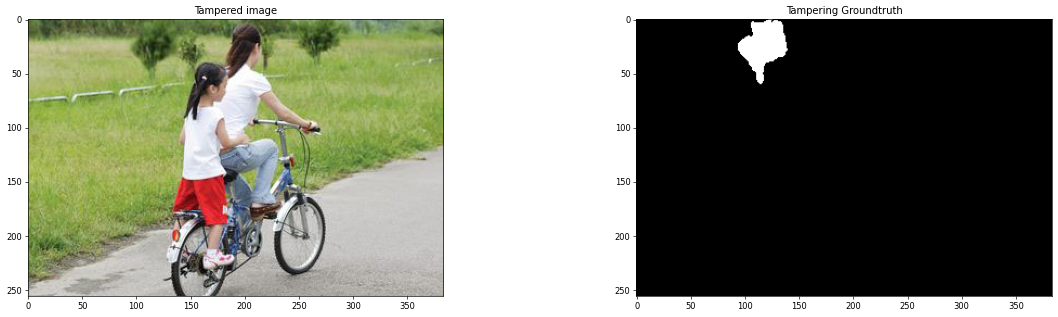

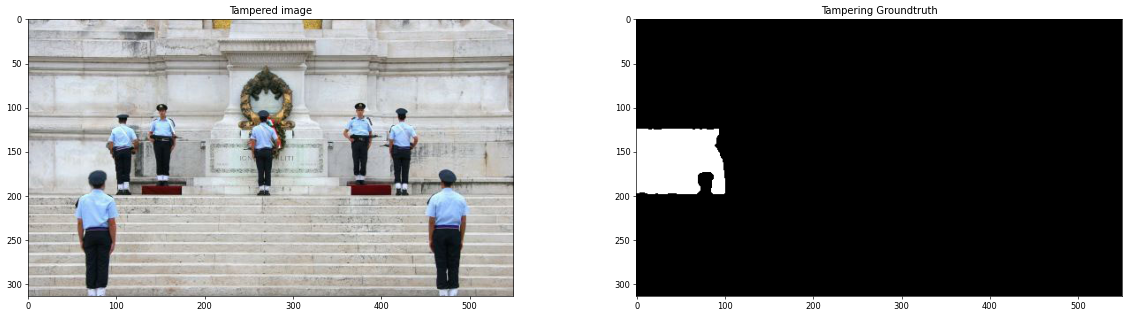

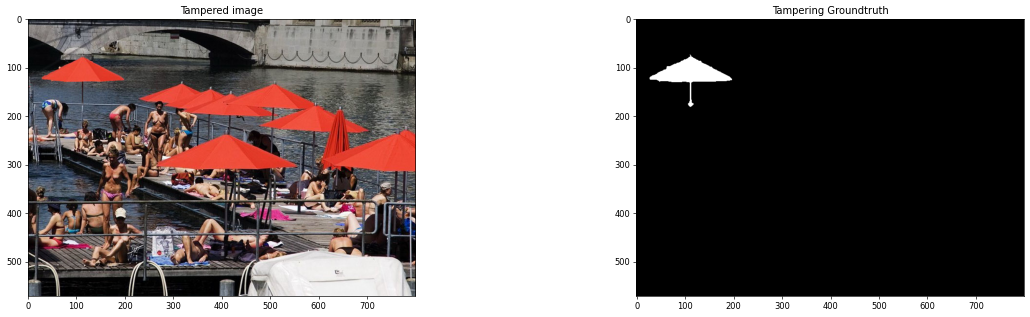

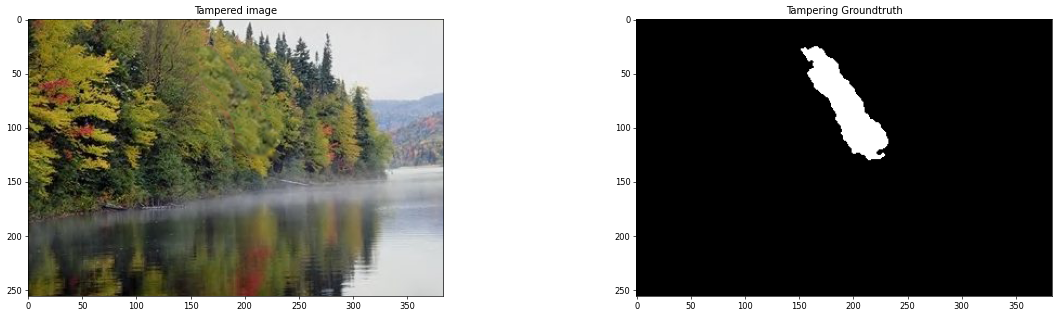

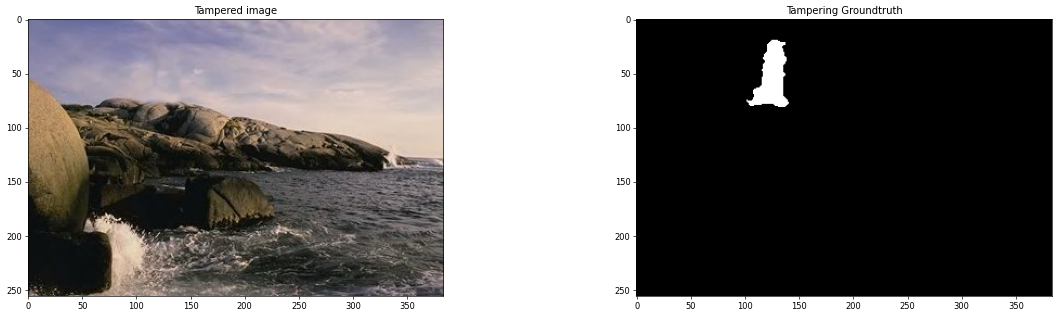

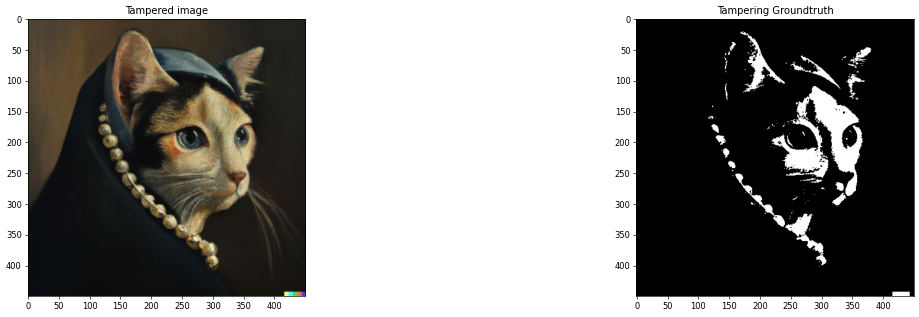

In [6]:
# Visualize datas without any augmentation
for img, gt in zip(dataset.tp_path, dataset.gt_path):
    img = plt.imread(img)
    gt = plt.imread(gt)
    plt.subplot(1, 2, 1)
    plt.title("Tampered image")
    plt.imshow(img)
    plt.subplot(1, 2, 2)
    plt.title("Tampering Groundtruth")
    plt.imshow(gt, cmap="gray")
    plt.show()

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


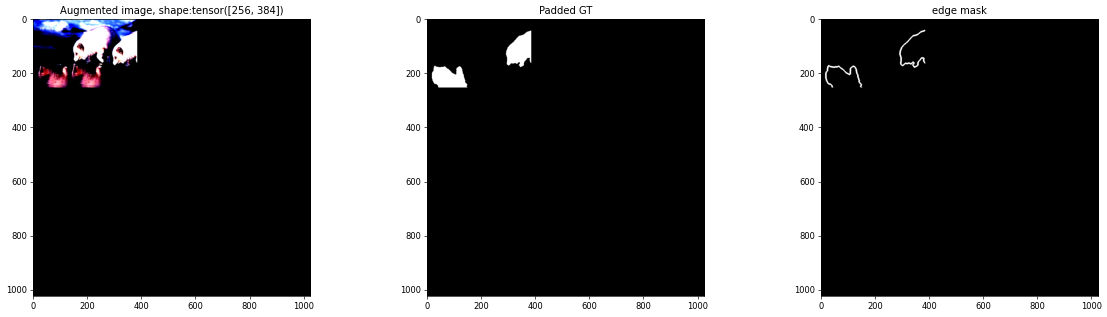

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


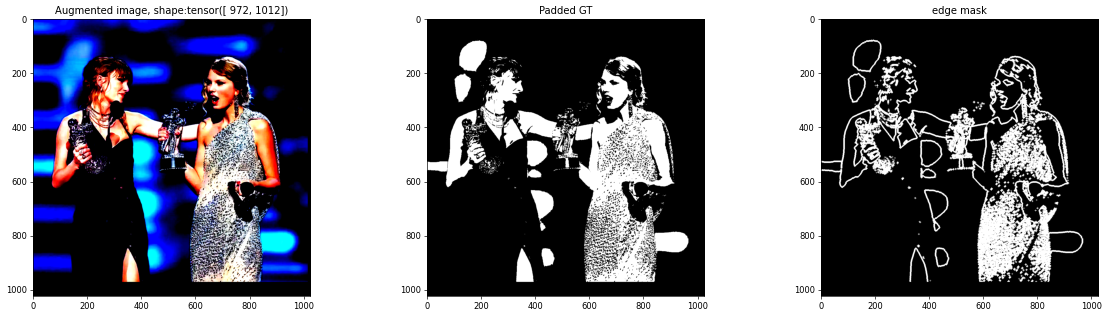

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


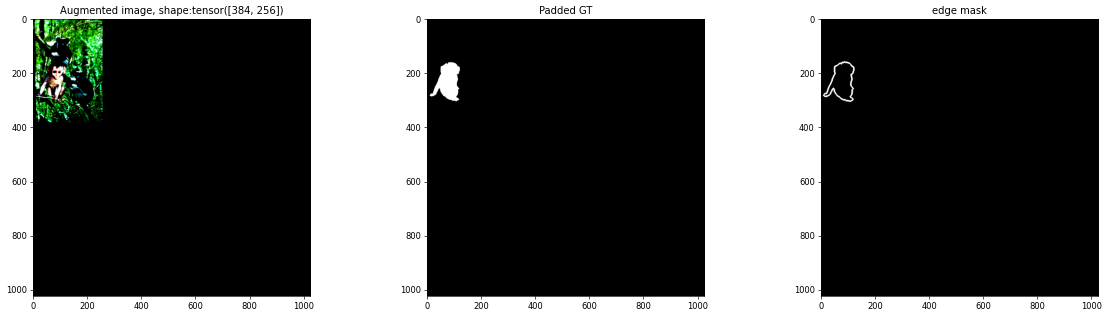

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


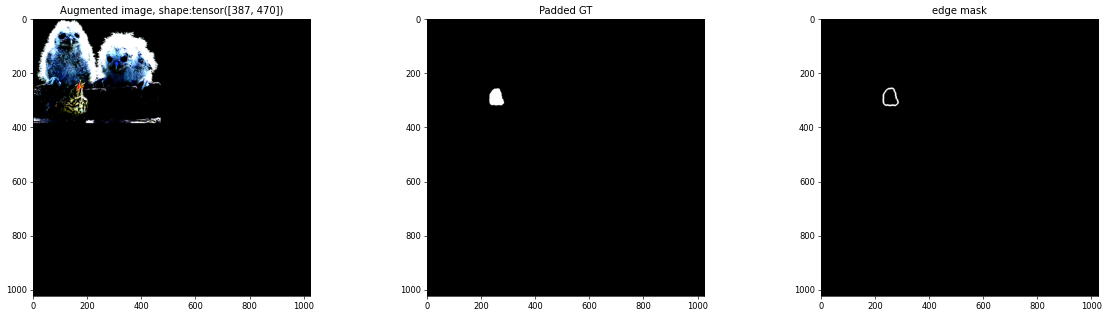

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


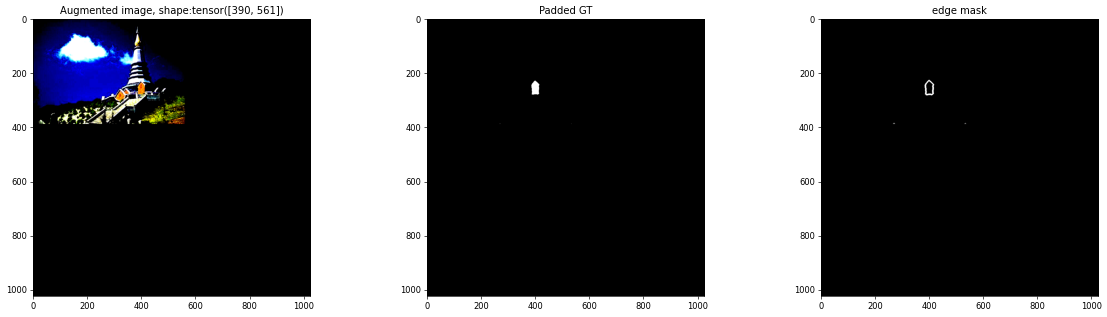

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


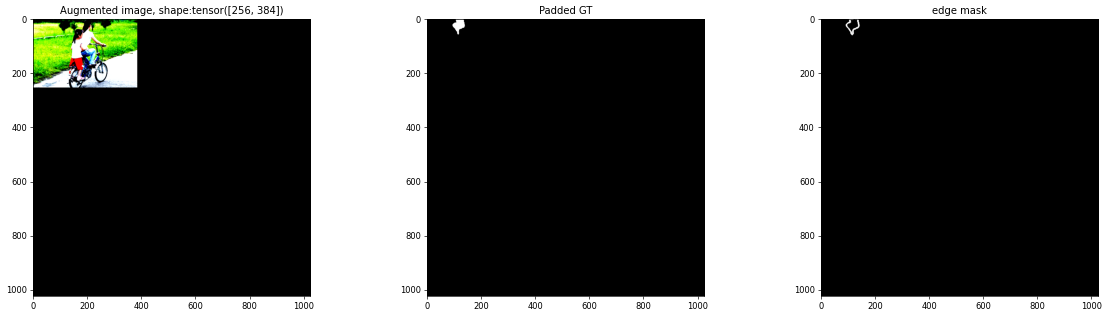

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


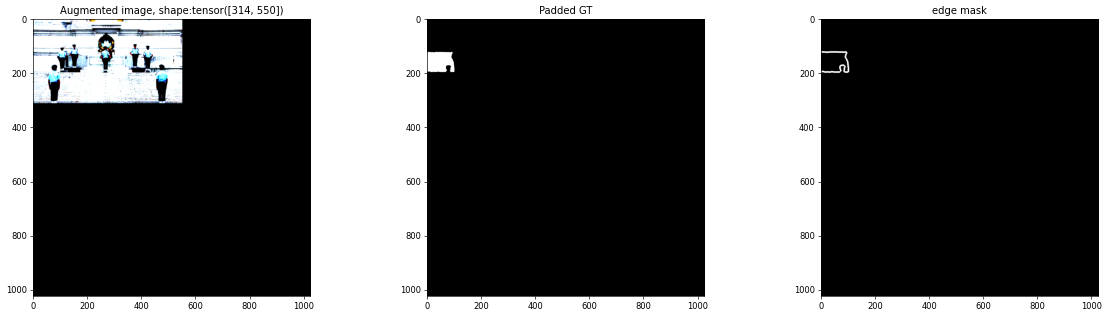

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


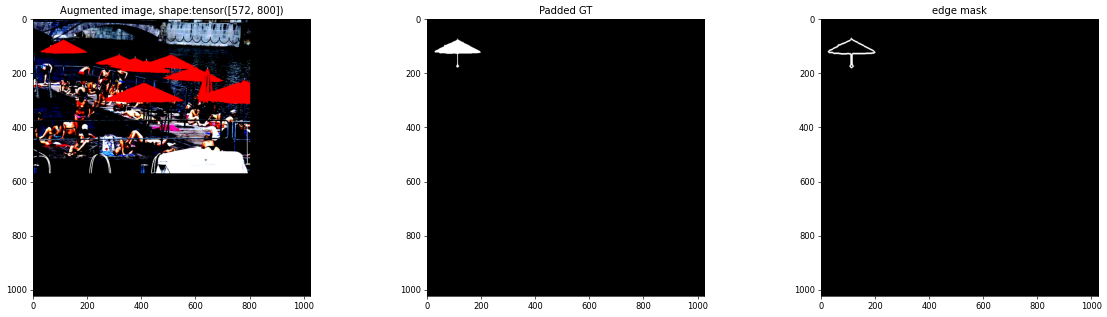

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


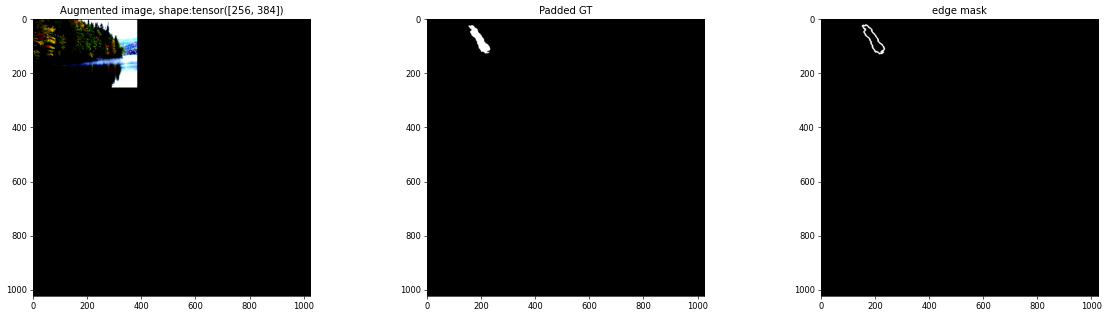

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


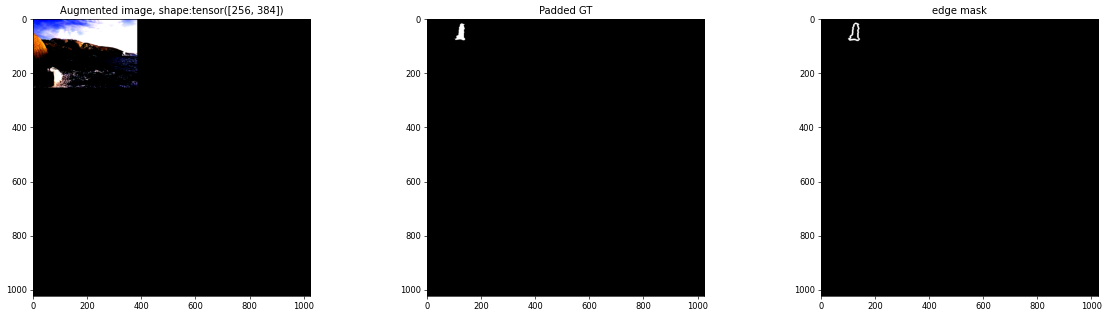

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


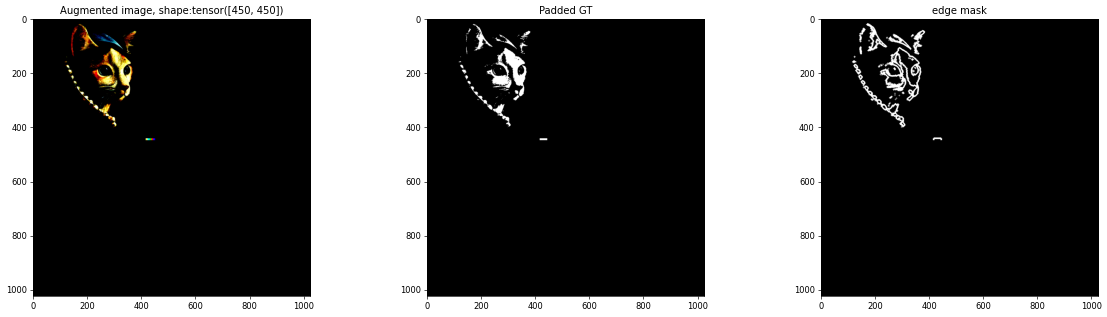

In [7]:
# Visualize after build-in transform (zero-padding and augmentations)
for img, gt, edge_mask, shape in dataset:
    plt.subplot(1, 3, 1)
    img = img.permute(1, 2, 0) # CHW -> HWC
    plt.imshow(img)
    plt.title(f"Augmented image, shape:{shape}")
    plt.subplot(1, 3, 2)
    gt = gt.permute(1, 2, 0) # CHW -> HWC
    plt.imshow(gt, cmap='gray')
    plt.title("Padded GT")
    plt.subplot(1, 3, 3)
    edge_mask = edge_mask.permute(1, 2, 0) # CHW -> HWC
    plt.imshow(edge_mask, cmap='gray')
    plt.title("edge mask")
    plt.show()

### Download the weights and init the IML-ViT model
You should download the pretrained weights from [Google Drive](https://drive.google.com/file/d/1xXJGJPW1i5j9Pc1JKd7fJmIAQkvt9jY7/view?usp=sharing) or [Baidu NetDisk](https://pan.baidu.com/s/1V-l1C6jCLBQTobrJcXDl7g?pwd=s835) and place it as `./checkpoints/iml-vit_checkpoint.pth`

In [8]:
import torch
from iml_vit_model import iml_vit_model

# Check if GPU is available
device = 'cuda' if torch.cuda.is_available() else 'cpu'
# device = 'cpu' # if out of memory, then uncommenting this line
#print("?:",torch.cuda.is_available())
print("Device:", device)
#print("PyTorch 版本:", torch.__version__)
ckpt_path = "./checkpoints/iml-vit_checkpoint.pth"
model = iml_vit_model()

model.load_state_dict(
    torch.load(ckpt_path),
    strict = False
)
model = model.to(device)

Device: cuda


### Inference
This process require your GPU has at least 6GB of memory.

shape: tensor([256, 384])


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


Predict Loss:0.024141200917343245, including edge loss: 0.021674405407237085


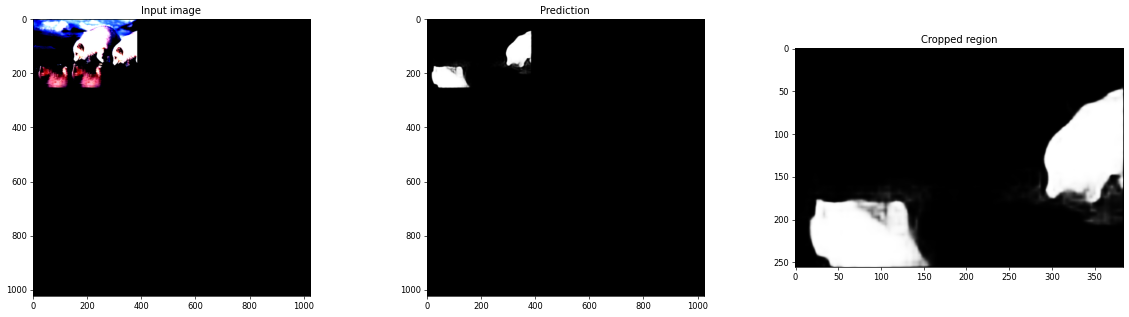

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


shape: tensor([ 972, 1012])
Predict Loss:18.757760910095087, including edge loss: 16.532077962790893


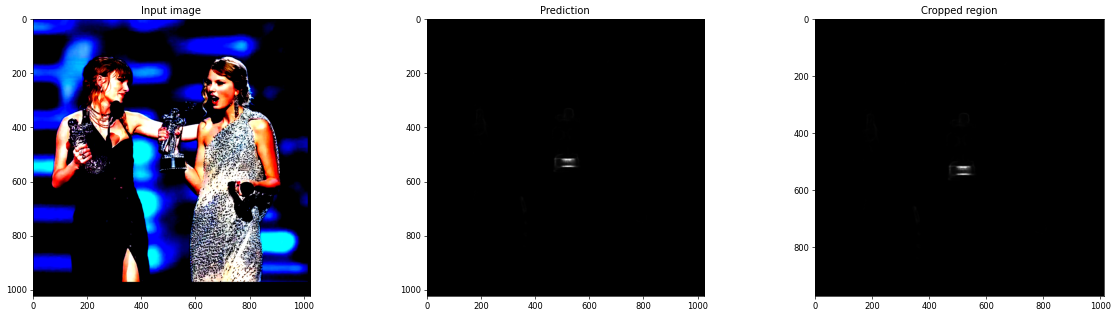

shape: tensor([384, 256])
Predict Loss:0.016984268194582357, including edge loss: 0.01571768791420347


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


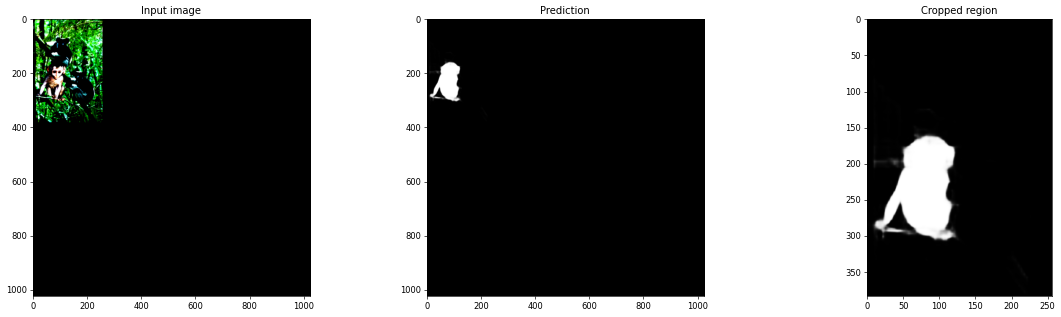

shape: tensor([387, 470])
Predict Loss:0.009996050066964569, including edge loss: 0.008577970441034921


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


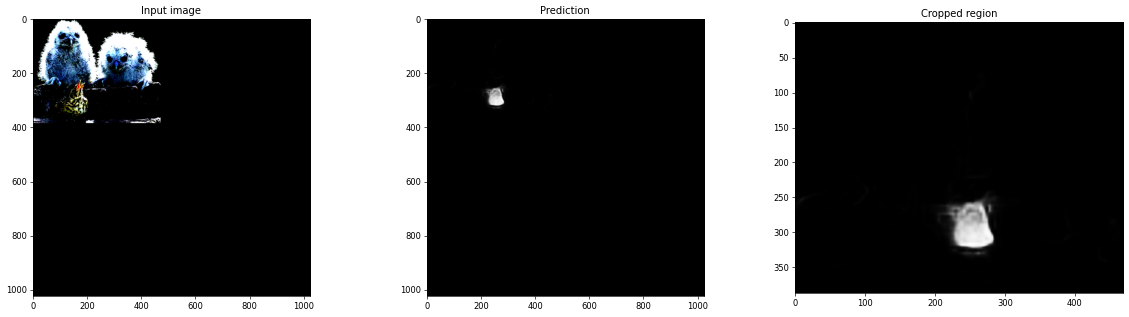

shape: tensor([390, 561])
Predict Loss:0.008115868069795059, including edge loss: 0.0075191257125503674


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


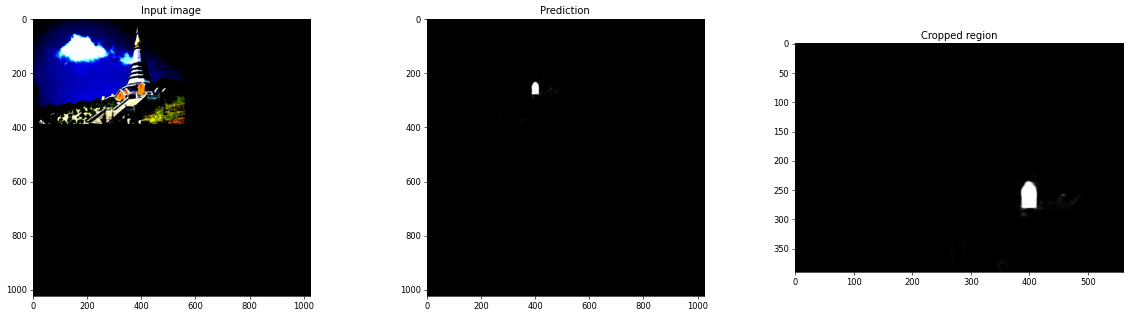

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


shape: tensor([256, 384])
Predict Loss:0.009833591097245183, including edge loss: 0.008092669532135943


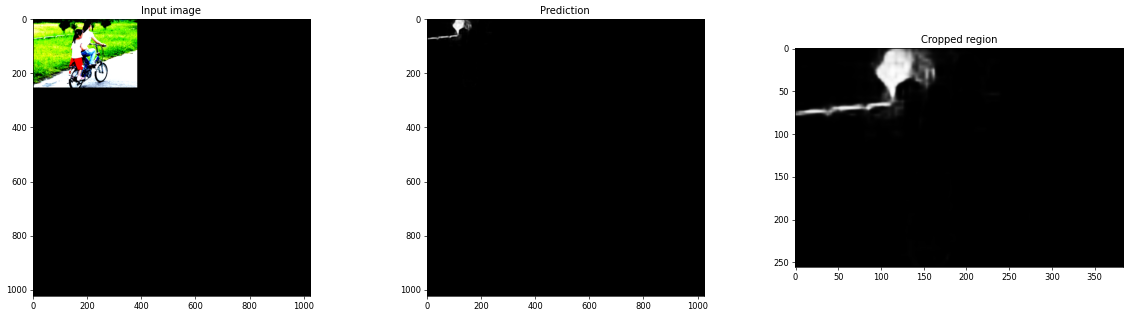

shape: tensor([314, 550])
Predict Loss:0.05949214276046535, including edge loss: 0.040576756492978205


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


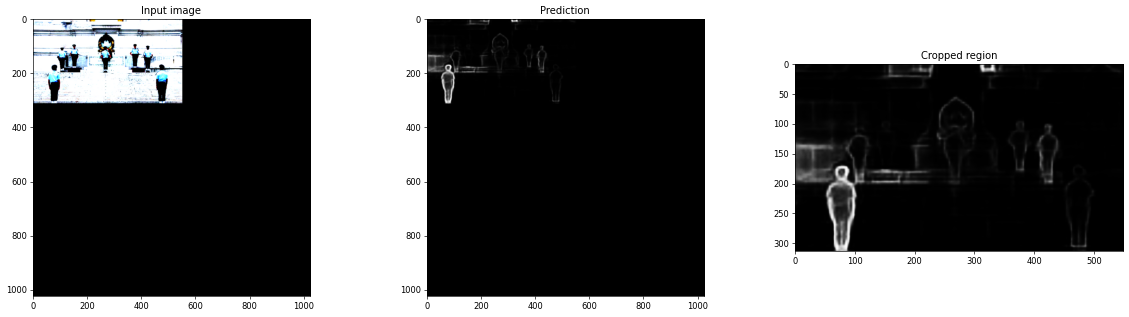

shape: tensor([572, 800])
Predict Loss:0.015628096326212683, including edge loss: 0.0137354080489719


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


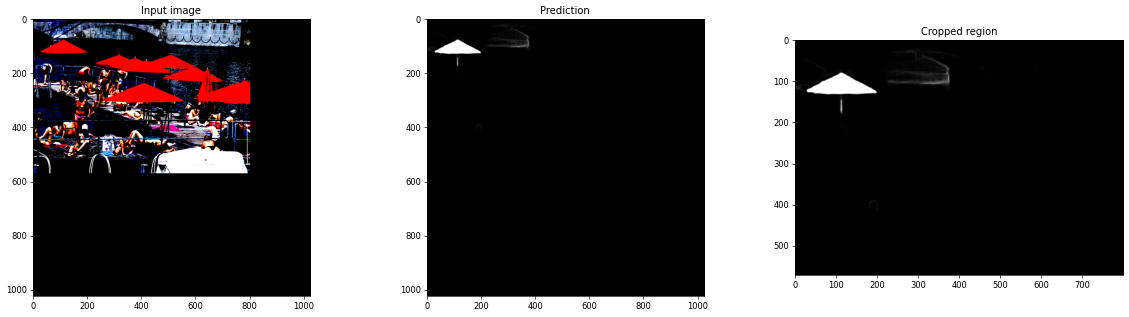

shape: tensor([256, 384])
Predict Loss:0.019199610953687905, including edge loss: 0.01746125306478774


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


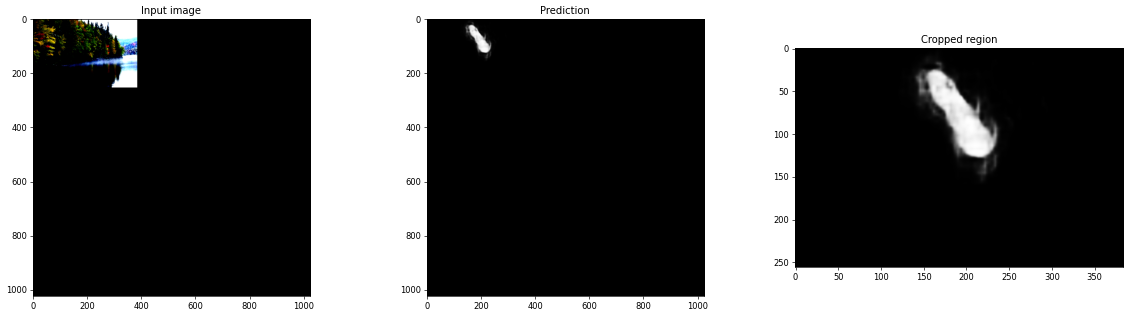

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


shape: tensor([256, 384])
Predict Loss:0.015721623621481988, including edge loss: 0.013785653189568592


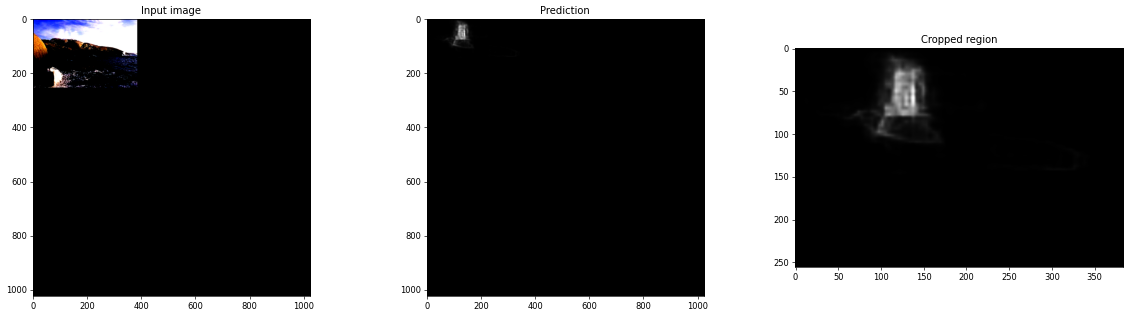

shape: tensor([450, 450])
Predict Loss:0.6364947651537217, including edge loss: 0.5686391462566098


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


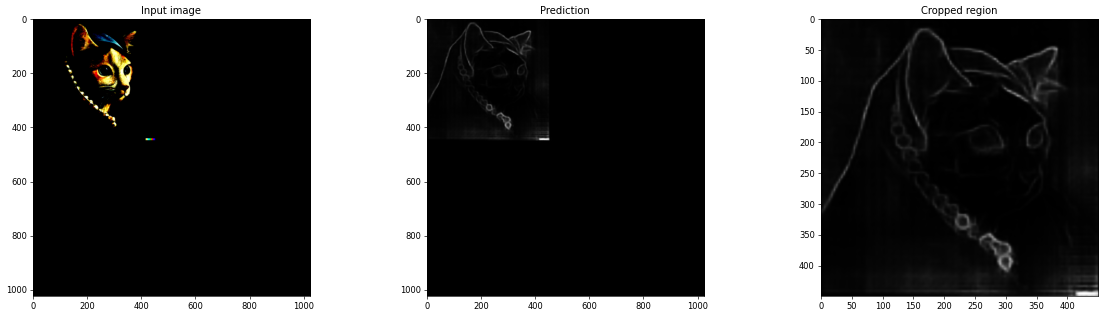

Done!


In [9]:
results = []
model.eval()
with torch.no_grad():
    for img, gt, edge_mask, shape in dataset:    # Inference don't need edge mask.
        img, gt, edge_mask = img.to(device), gt.to(device), edge_mask.to(device)
        # Since no Dataloader, manually create a Batch with size==1
        img = img.unsqueeze(0) # CHW -> 1CHW
        gt = gt.unsqueeze(0)
        edge_mask = edge_mask.unsqueeze(0)
        print("shape:", shape)
        # inference 使用模型执行测试图片
        predict_loss, mask_pred, edge_loss = model(img, gt, edge_mask)
        print(f"Predict Loss:{predict_loss}, including edge loss: {edge_loss}")
        output = mask_pred
        
        # visualize
        plt.subplot(1, 3, 1)
        plt.title("Input image")
        plt.imshow(img[0].permute(1, 2, 0).cpu().numpy())
        plt.subplot(1, 3, 2)
        plt.title("Prediction")
        plt.imshow(output.cpu().numpy()[0][0], cmap='gray')


        # Cut the origin area from padded image
        #第一个维度选择第一个元素，张量的第一个维度通常表示批处理的数量，这里是对单个文件进行处理
        #第二个维度通常表示通道维度，一共RGB三个通道
        #第三个维度从0到原始图像的高
        #第四个维度从0到原始图像的宽
        #对维度进行置换，从 (通道数，高度，宽度) 的顺序变为 (高度，宽度，通道数)，适合显示图像
        #例如在将张量转换为 NumPy 数组时，需要将张量从 GPU 上移动到 CPU 内存上，因为 NumPy 操作不支持在 GPU 上执行.cpu() 方法就是用来实现这个目的的。.numpy将张量转换为numpy数组。
        output = output[0, :, 0:shape[0], 0:shape[1]].permute(1, 2, 0).cpu().numpy()
        results.append(output)
        plt.subplot(1, 3, 3)
        plt.title("Cropped region")
        plt.imshow(output, cmap='gray')
        plt.show()
print("Done!")

### Thresholding & comparison

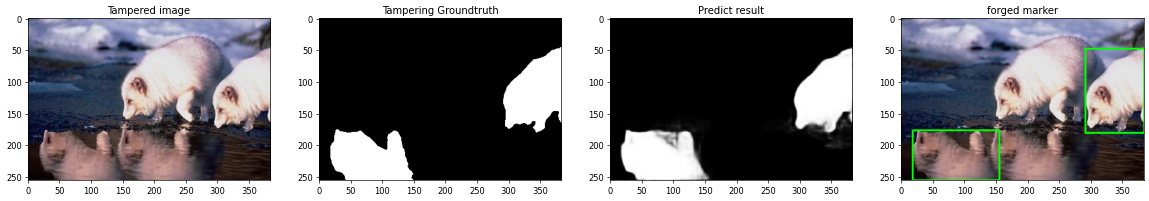

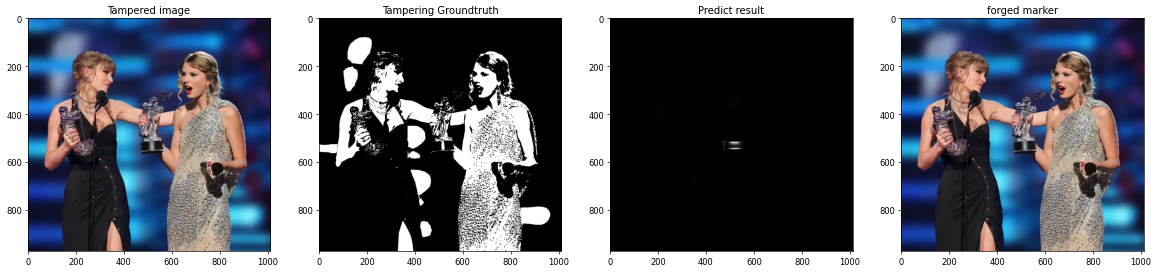

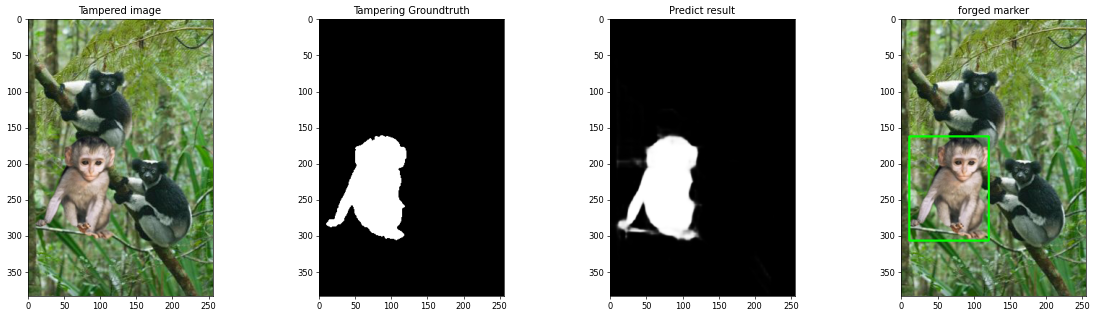

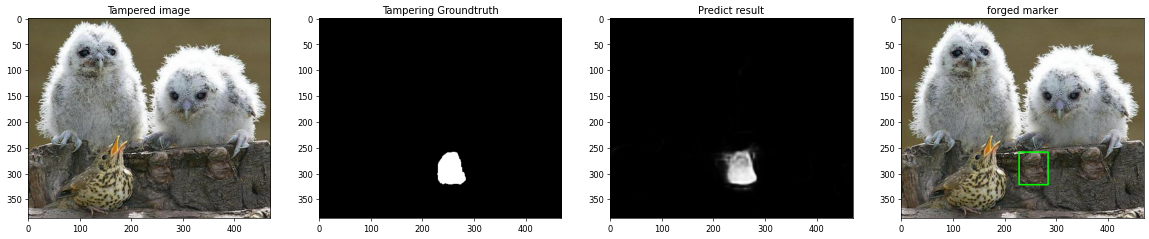

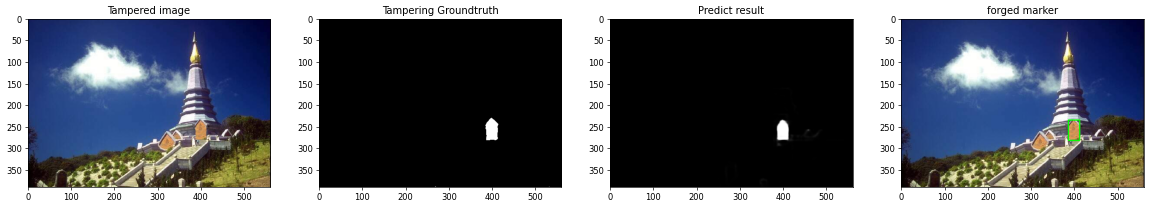

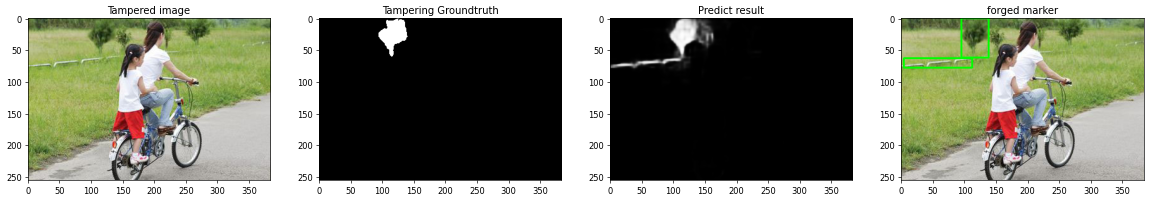

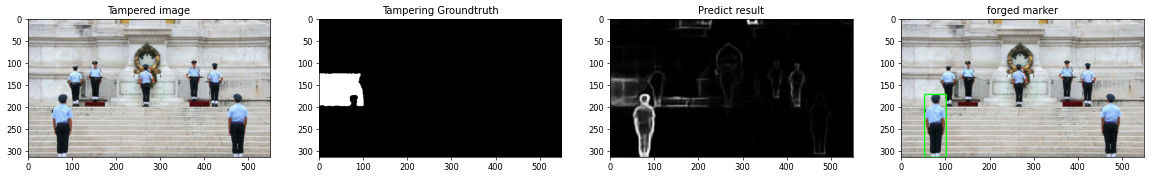

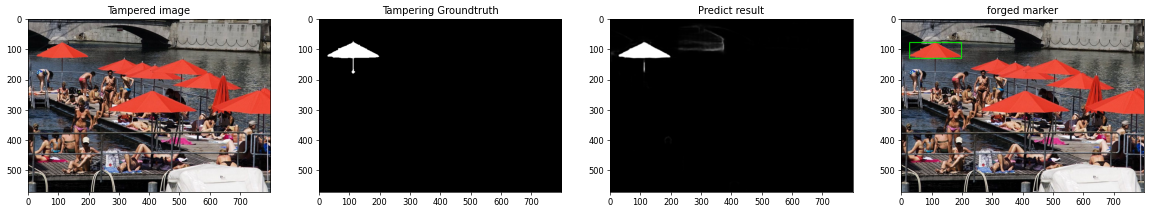

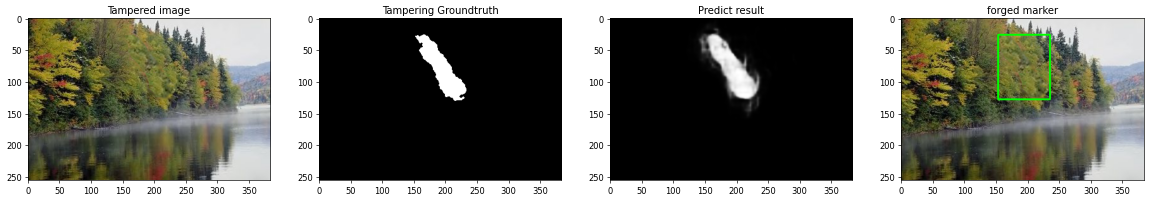

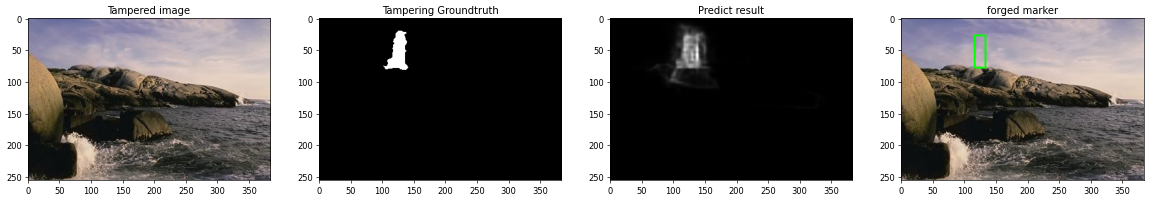

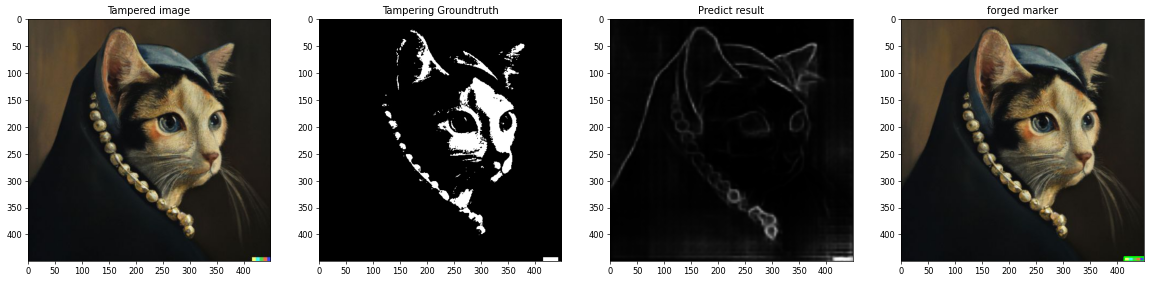

In [10]:
import numpy as np
import cv2

# Visualize the results:
for img, gt, res in zip(dataset.tp_path, dataset.gt_path, results): 

    # 查看 res 的数据类型
    #print(res.dtype)
    img = plt.imread(img)
    gt = plt.imread(gt)
    plt.subplot(1, 4, 1)
    plt.title("Tampered image")
    plt.imshow(img)
    plt.subplot(1, 4, 2)
    plt.title("Tampering Groundtruth")
    plt.imshow(gt, cmap="gray")
    plt.subplot(1, 4, 3)
    plt.title("Predict result")
    plt.imshow(res, cmap="gray")
    #plt.subplot(1, 4, 4)
    #plt.title("Result after thresholding")
    
    plt.subplot(1, 4, 4)
    plt.title("forged marker")
    # 将 res 转换为 uint8 类型
    res_uint8 = (res * 255).astype('uint8')
    #print(res_uint8.dtype)
    #模型返回的本身是单通道的灰度图片，无需进行RGB2GRAY
    #获得0/1图片
    _, binary = cv2.threshold(res_uint8, 255*0.5, 255, cv2.THRESH_BINARY)
    #寻找轮廓
    contours,_=cv2.findContours(binary,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
    #复制原来的彩色图片
    img_copy = img.copy()
    #遍历判断每一个轮廓
    for contour in contours:
       # 轮廓边界
       x,y,w,h=cv2.boundingRect(contour)
       area=cv2.contourArea(contour)
       min_area=200
       if area>min_area:
           cv2.rectangle(img_copy,(x,y),(x+w,y+h),(0,255,0),2)
    plt.imshow(img_copy)
    plt.show()
    #plt.imshow(res > 0.5, cmap="gray")
    #plt.show()